In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df = pd.read_csv("../data/raw/train.csv")

df['date'] = pd.to_datetime(df['date'])

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
#daily sales time series

daily_sales = df.groupby('date')['sales'].sum()

daily_sales.head()

date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Name: sales, dtype: int64

In [5]:
print("Start Date:" , daily_sales.index.min())
print("End Date:", daily_sales.index.max())

print("Total Days:", len(daily_sales))

print("AVerage Daily Sales:", daily_sales.mean())



Start Date: 2013-01-01 00:00:00
End Date: 2017-12-31 00:00:00
Total Days: 1826
AVerage Daily Sales: 26125.143483023003


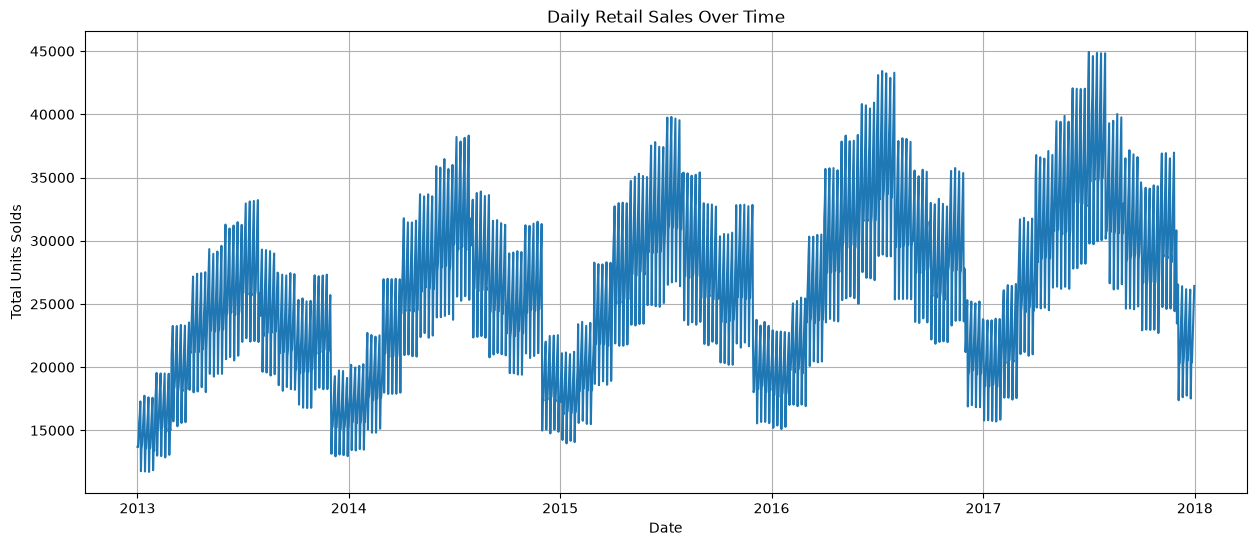

In [6]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales.index,
    daily_sales.values
)

plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Units Solds")

plt.grid(True)
plt.show()

In [7]:
daily_sales_7d = daily_sales.rolling(window=7).mean()
daily_sales_30d = daily_sales.rolling(window=30).mean()

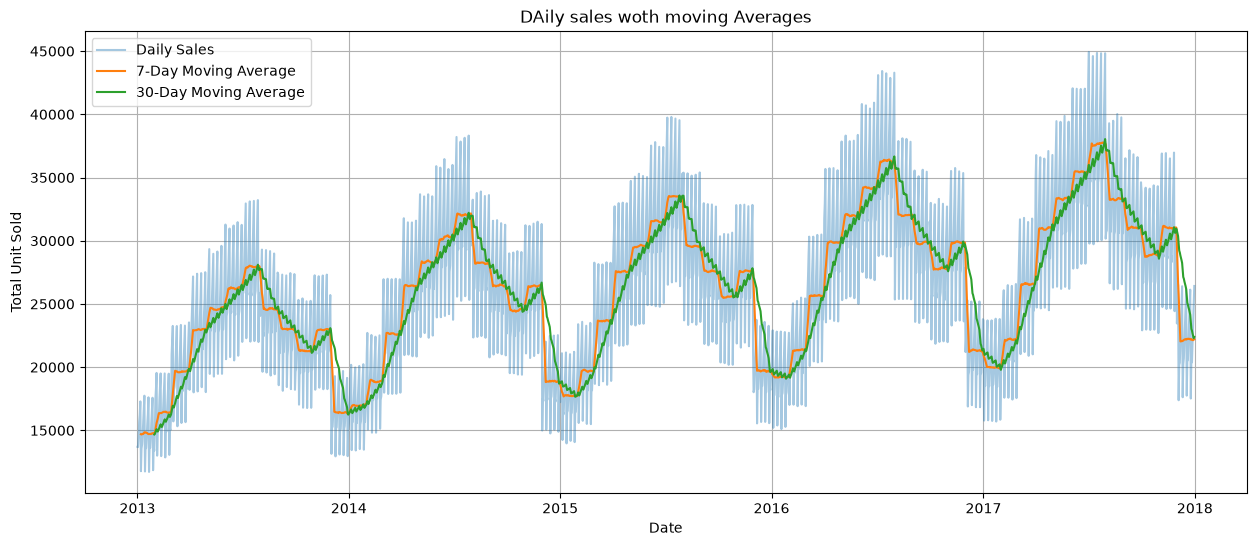

In [11]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    label="Daily Sales",
    alpha=0.4
)

plt.plot(
    daily_sales_7d.index,
    daily_sales_7d.values,
    label = "7-Day Moving Average"
)

plt.plot(
    daily_sales_30d.index,
    daily_sales_30d.values,
    label="30-Day Moving Average"
)

plt.title("DAily sales woth moving Averages")
plt.xlabel("Date")
plt.ylabel("Total Unit Sold")

plt.legend()
plt.grid(True)

plt.show()

In [12]:
print("Total Daily obsevation:",len(daily_sales))

print("Frist date:",daily_sales.index.min())
print("Last date:",daily_sales.index.max())

print("FRequency between observation:")
print(daily_sales.index.to_series().diff().value_counts().head())

Total Daily obsevation: 1826
Frist date: 2013-01-01 00:00:00
Last date: 2017-12-31 00:00:00
FRequency between observation:
date
1 days    1825
Name: count, dtype: int64


In [13]:
#learn till this 
"""
Daily sales flutuate siginificanlty
Daily fluctutaions make the graph look noise 
Moving averages help smooth the noise 
the 7 day average captures shorter term changes 
the 30 day average revaels broder trends """

'\nDaily sales flutuate siginificanlty\nDaily fluctutaions make the graph look noise \nMoving averages help smooth the noise \nthe 7 day average captures shorter term changes \nthe 30 day average revaels broder trends '

In [27]:
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekly_pattern = daily_sales.groupby(
    daily_sales.index.day_name()
).mean()

weekly_pattern = weekly_pattern.reindex(days_order)

print(weekly_pattern)
    

date
Monday       20714.819231
Tuesday      24112.954023
Wednesday    24184.252874
Friday       27578.624521
Saturday     29331.348659
Sunday       31071.666667
Name: sales, dtype: float64


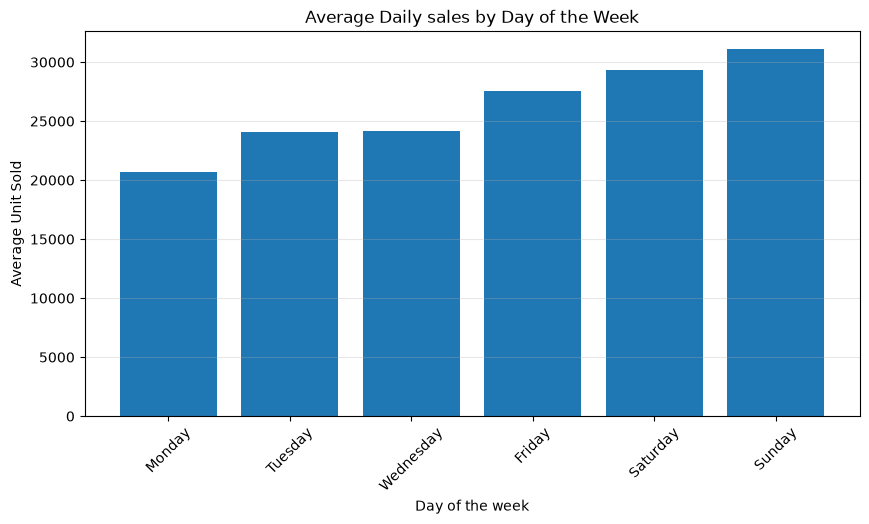

In [28]:
plt.figure(figsize=(10,5))

plt.bar(
    weekly_pattern.index,
    weekly_pattern.values
)

plt.title("Average Daily sales by Day of the Week")
plt.xlabel("Day of the week")
plt.ylabel("Average Unit Sold")

plt.xticks(rotation=45)
plt.grid(axis='y',alpha=0.3)

plt.show()

In [29]:
print("Highest sales day:",weekly_pattern.idxmax())
print("Lowest sales day:",weekly_pattern.idxmin())

print("Highest average sales",weekly_pattern.max())
print("Lowest average sales",weekly_pattern.min())

Highest sales day: Sunday
Lowest sales day: Monday
Highest average sales 31071.666666666668
Lowest average sales 20714.81923076923


KeyError: 'Wednesday'

date
Monday      20714.819231
Tuesday     24112.954023
Wenesday             NaN
Friday      27578.624521
Satarday             NaN
Sunday      31071.666667
Name: sales, dtype: float64

Index values:
['Monday', 'Tuesday', 'Wenesday', 'Friday', 'Satarday', 'Sunday']


date
Friday       27578.624521
Monday       20714.819231
Saturday     29331.348659
Sunday       31071.666667
Thursday     25861.609195
Tuesday      24112.954023
Wednesday    24184.252874
Name: sales, dtype: float64


date
Monday       20714.819231
Tuesday      24112.954023
Wednesday    24184.252874
Thursday     25861.609195
Friday       27578.624521
Saturday     29331.348659
Sunday       31071.666667
Name: sales, dtype: float64


In [32]:
#Average sales by month

monthly_pattern = daily_sales.groupby(
    daily_sales.index.month
).mean()

monthly_pattern.index = [
    'January', 'February' , 'March' , 'April',
    'May' , 'June' , 'July' , 'August' , 
    'September','October' , 'November' , 'December' ]

print(monthly_pattern)

January      17762.251613
February     19689.198582
March        23652.787097
April        27576.446667
May          29564.109677
June         31512.740000
July         33499.309677
August       29552.612903
September    27536.380000
October      25596.903226
November     27609.040000
December     19682.632258
Name: sales, dtype: float64


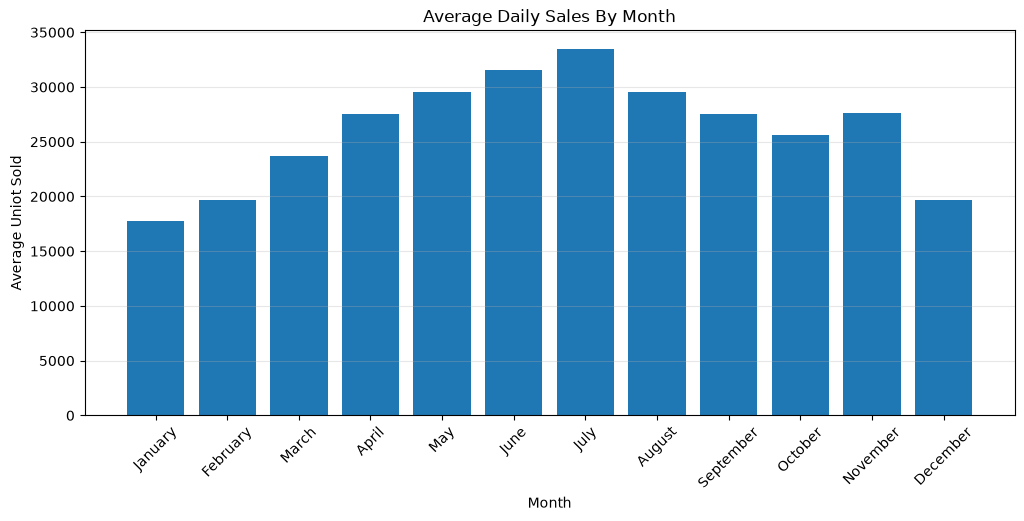

In [34]:
plt.figure(figsize=(12,5))

plt.bar(monthly_pattern.index , monthly_pattern.values)

plt.title("Average Daily Sales By Month")
plt.xlabel("Month")
plt.ylabel("Average Uniot Sold")

plt.xticks(rotation=45)
plt.grid(axis = 'y' , alpha=0.3)

plt.show()

In [36]:
print("Highest sales month:",monthly_pattern.idxmax())
print("Lowest sales month:",monthly_pattern.idxmin())

print("Highest average sales:", monthly_pattern.max())
print("Lowest average sales:",monthly_pattern.min())

Highest sales month: July
Lowest sales month: January
Highest average sales: 33499.309677419355
Lowest average sales: 17762.251612903226


In [37]:
#Time Series Decomposition
#decompostion seprates a time series into three main compononets 
#1)Trend-----------> long term dicrection of sales . increasing or decreasing 
#2)Seasonality-----> Repeating pettern such weekly or yearly sales changes
#3)Residual(Noise)-> Random variation that the trend and seasonal pattern do not explain

In [39]:
#importing decompostion
from statsmodels.tsa.seasonal import seasonal_decompose 

In [41]:
decomposition = seasonal_decompose(
    daily_sales,
    model = 'additive',
    period = 7
)

<Figure size 2500x1000 with 0 Axes>

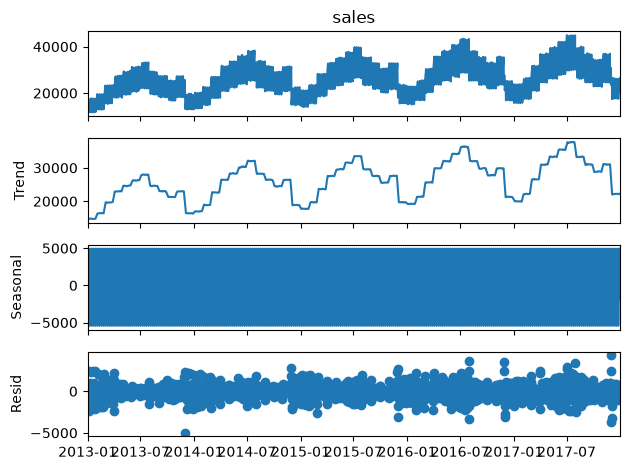

In [44]:
plt.figure(figsize=(25,10))

decomposition.plot()

plt.show()

In [45]:
#Stationarity---->when time series series statistical properties remain approximatly constant over time 
#mean-->average remains relatively constant 
#variace spread of values reamins relatively constant 
# autocovairce-->realtionship btn observation depaends on time gap not the date 

In [47]:
rolling_mean = daily_sales.rolling(window=30).mean()

rolling_std = daily_sales.rolling(window=30).std()

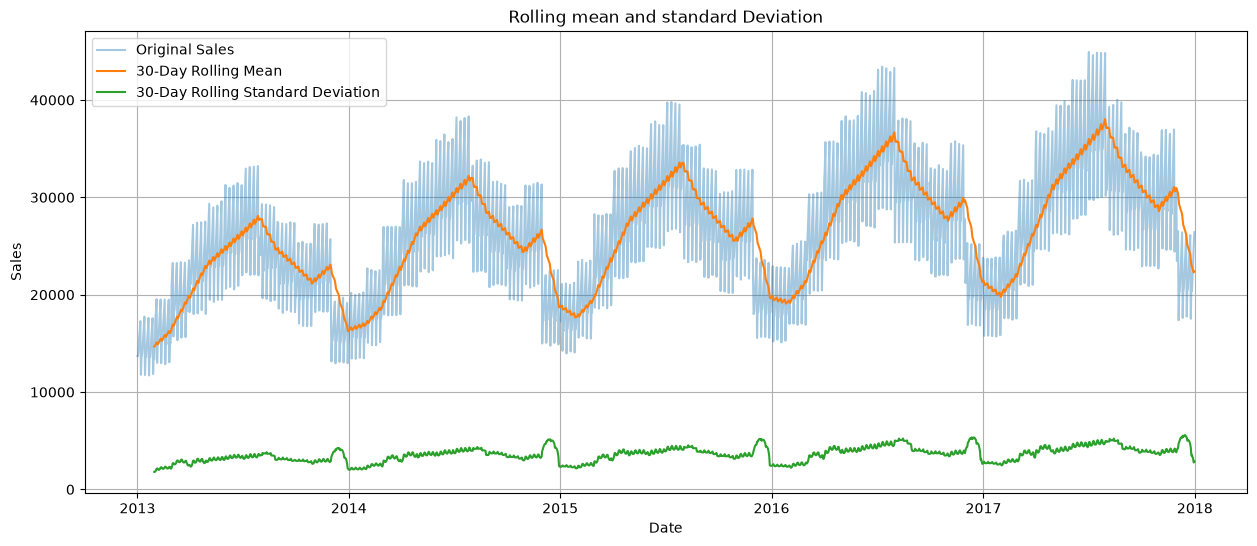

In [50]:
plt.figure(figsize=(15,6))

plt.plot(daily_sales, label="Original Sales",alpha=0.4)
plt.plot(rolling_mean, label="30-Day Rolling Mean")
plt.plot(rolling_std, label="30-Day Rolling Standard Deviation")

plt.title("Rolling mean and standard Deviation")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

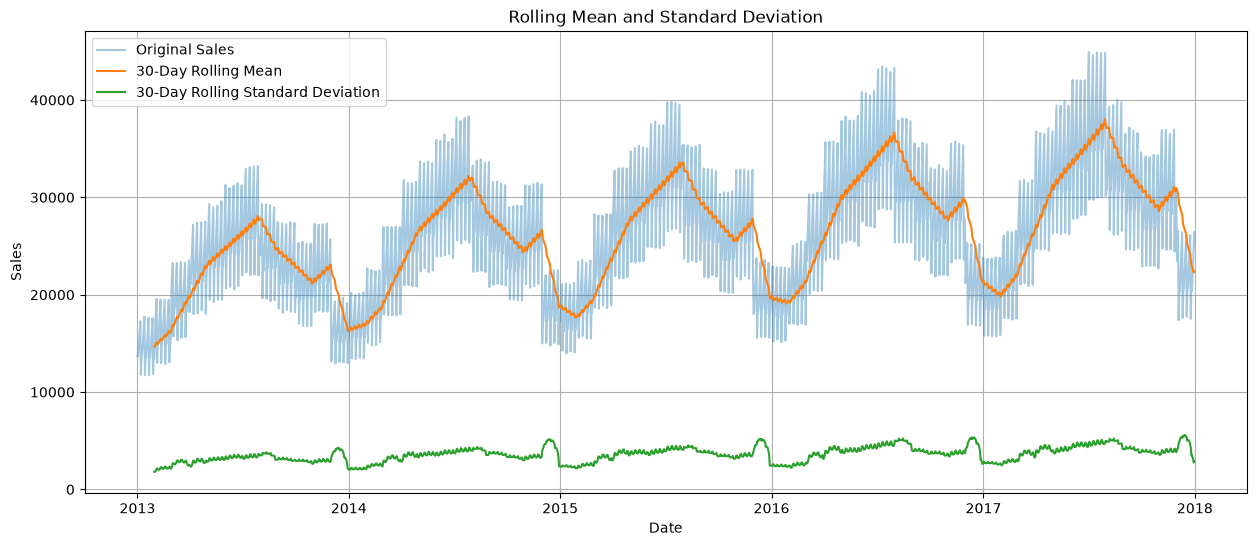